# 03 - A cheaper TabPFN (v2, v3)

TabPFN is the most accurate classifier on QUANT's features (notebook 02) but about 30 times slower than ExtraTrees.
Three steps make it cheaper: fewer passes and features (v2), building its model once (the model cache), and a lean
extractor for it (v3). The small and medium datasets, resamples 0 to 2. Settings and commands: `experiments.md`, v2
and v3.

## 1. Data

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# the shared names, colours, plot style and loading of all notebooks: notebooks/common.py
from common import (BETTER, COLORS, EQUAL, MUTED, RESULTS_DIR, TEXT, VERSION_COLORS, WORSE, load_runs, signed,
                    style, wdl_counts)

style()
GROUPS = ["small", "medium"]           # the two dataset lists; every section shows both
key = ["dataset", "resample"]          # one run = one dataset and one resample

def load(name):
    """The finished runs of a file in results/ (with the time columns of common.load_runs)."""
    d = load_runs(RESULTS_DIR / name)
    return d[d["status"] == "ok"]

# the v2 configurations (TabPFN on QUANT's features, one file each)
ALL_CONFIGS = ["tabpfn-e8f500", "tabpfn-e4f500", "tabpfn-e2f500", "tabpfn-e1f500", "tabpfn-e8f200", "tabpfn-e2f200"]

def sweep_file(config, group, tag=""):
    """The file of a configuration; tag "-cache": the same configuration with TabPFN's model cache."""
    return f"v2_{config}{tag}_smoke-{group}_allcores-gpu.csv"

SWEEP, V1 = {}, {}
for group in GROUPS:
    SWEEP[group] = pd.concat([load(sweep_file(c, group)).assign(classifier=c) for c in ALL_CONFIGS], ignore_index=True)
    V1[group] = load(f"v1_smoke-{group}_allcores-gpu.csv")        # v1: all four classifiers on QUANT's features

def sweep_runs(group):
    """The sweep's TabPFN runs, with v1's ExtraTrees runs as the reference ("extratrees")."""
    v1 = V1[group]
    return pd.concat([SWEEP[group], v1[v1["classifier"] == "extratrees"]], ignore_index=True)

def group_title(fig, group, top=0.95):
    """Name the dataset list above a figure."""
    fig.suptitle(f"{group} datasets", x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, top))

def stacked_wdl(ax, names, counts, title):
    """Horizontal stacked bars: the better / equal / worse counts of every name, each part labelled with its count."""
    y = np.arange(len(names))[::-1]
    left = np.zeros(len(names))
    for k, (label, color) in enumerate([("better", BETTER), ("equal", EQUAL), ("worse", WORSE)]):
        values = np.array([c[k] for c in counts], dtype=float)
        bars = ax.barh(y, values, left=left, color=color, edgecolor="white", label=label)
        ax.bar_label(bars, labels=[f"{v:.0f}" if v > 0 else "" for v in values], label_type="center", fontsize=9,
                     color=TEXT if color == EQUAL else "white")
        left += values
    ax.set_yticks(y, names)
    ax.set_xlabel("runs")
    ax.set_title(title, loc="left")
    ax.grid(False)
    ax.legend(loc="upper center", frameon=False, ncol=3, fontsize=8.5, bbox_to_anchor=(0.5, -0.12))

def config_label(c, lines=True):
    """e.g. "tabpfn-e2f500" -> "TabPFN, 2 passes, 500 feat." (lines=True: one line per part)."""
    if c == "extratrees":
        return "ExtraTrees\n(v1)" if lines else "ExtraTrees (v1)"
    passes, features = re.fullmatch(r"tabpfn-e(\d+)f(\d+)", c).groups()
    text = f"TabPFN, {passes} pass{'es' if int(passes) > 1 else ''}, {features} feat."
    return text.replace(", ", "\n") if lines else text

## 2. Passes and features: accuracy and cost of each TabPFN configuration

Means over the 15 runs of each configuration; ExtraTrees (v1) in blue; 2 passes x 200 features (kept for v3 and v4)
outlined. Bottom right: better / equal / worse runs than ExtraTrees.

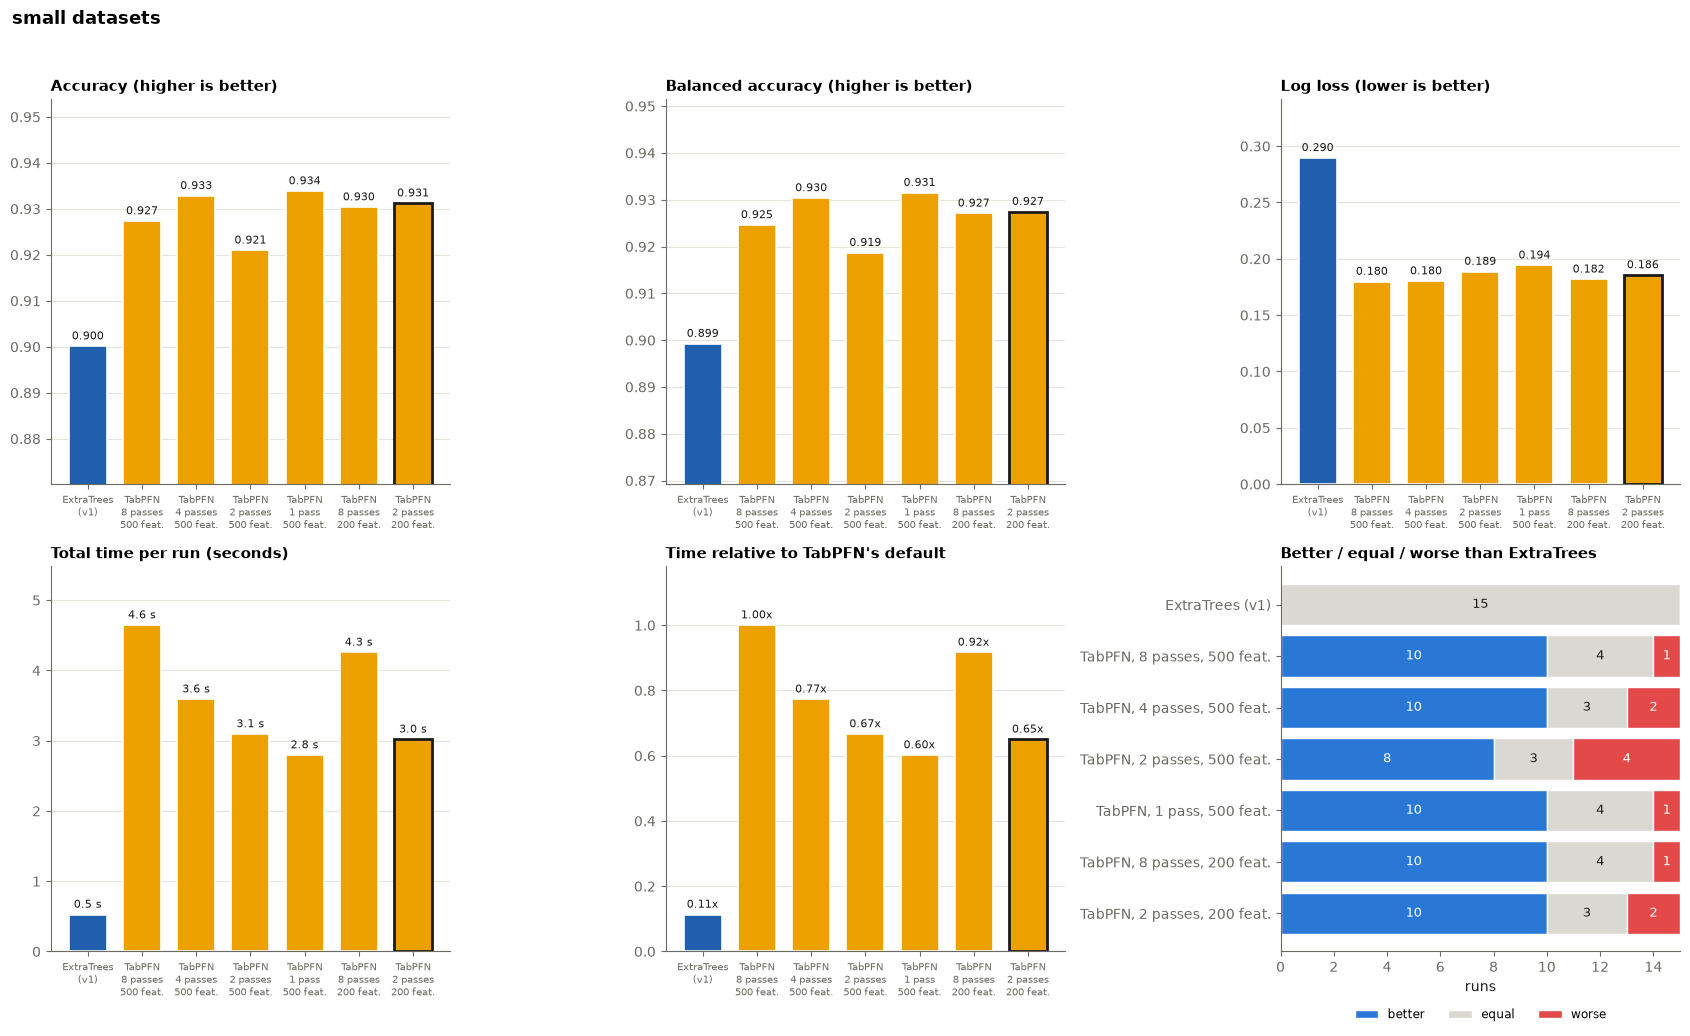

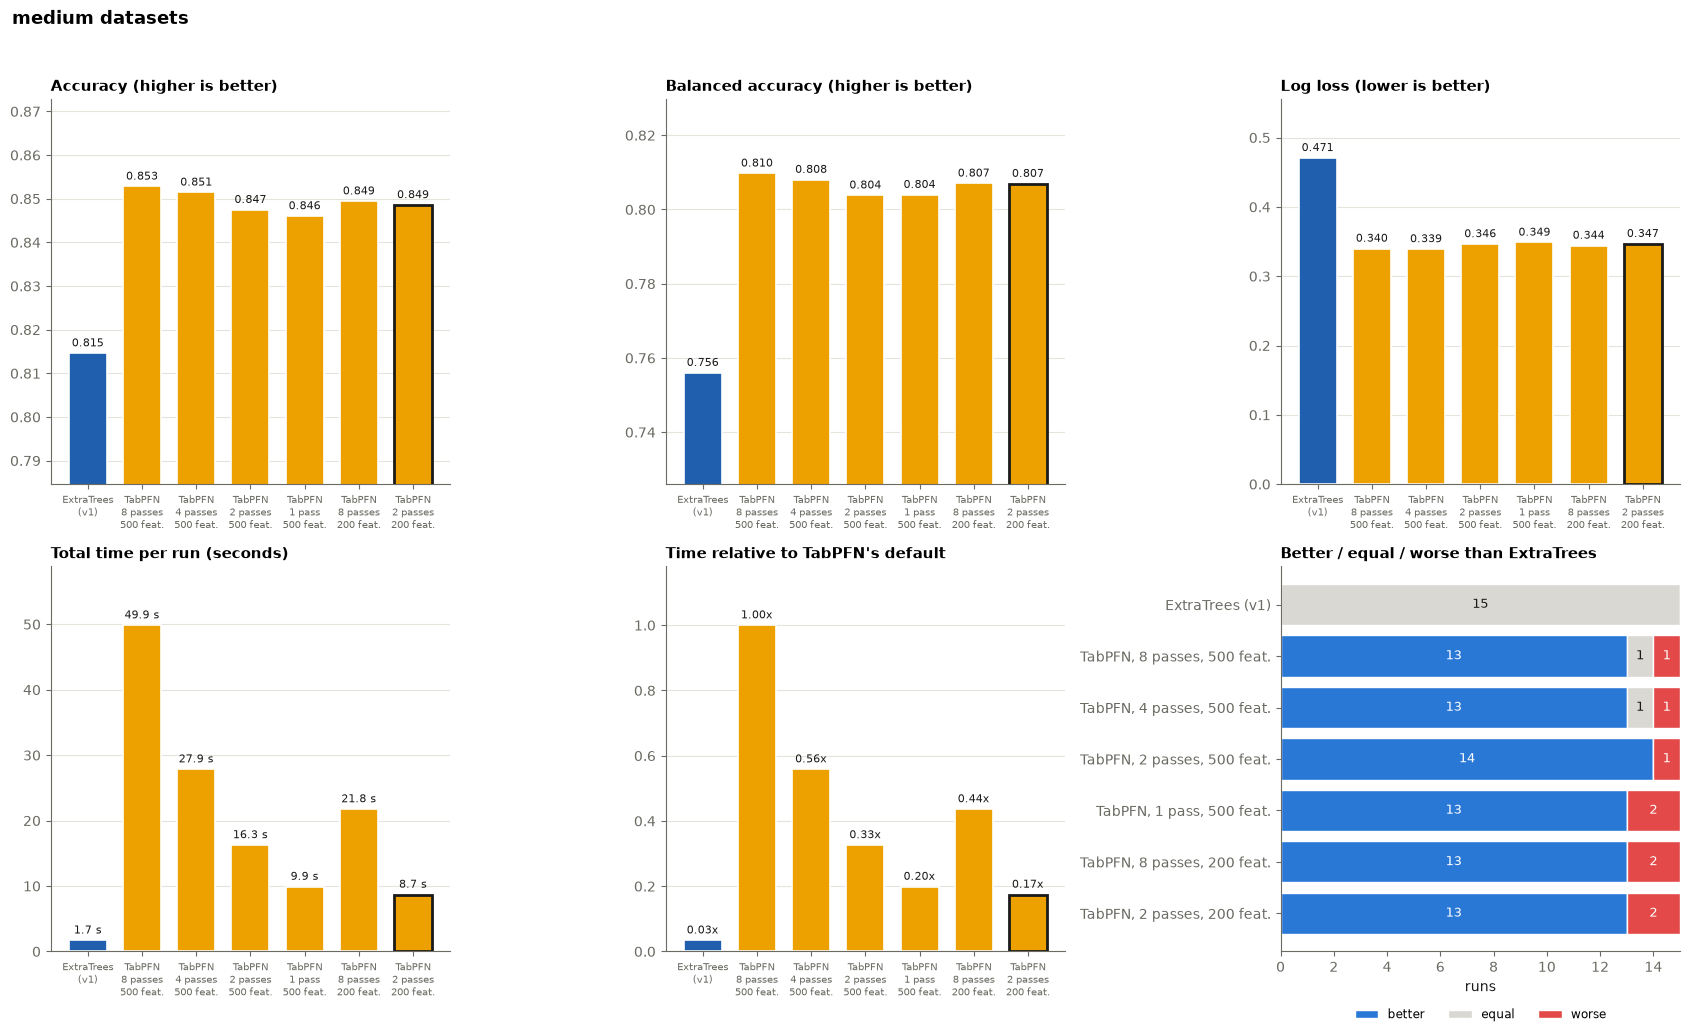

In [2]:
MAIN, PER_CONFIG = {}, {}              # per list: the configurations without a context cap, and their means
for group in GROUPS:
    runs = sweep_runs(group)
    main = MAIN[group] = ["extratrees"] + ALL_CONFIGS
    per_config = runs[runs["classifier"].isin(main)].groupby("classifier")[
        ["accuracy", "balanced_accuracy", "log_loss", "total_time"]].mean().reindex(main)
    paired = runs.pivot_table(index=key, columns="classifier", values=["accuracy", "total_time"])   # one row per run
    per_config["time vs default"] = [paired[("total_time", c)].sum() / paired[("total_time", "tabpfn-e8f500")].sum()
                                     for c in main]
    PER_CONFIG[group] = per_config
    wdl_vs_et = [wdl_counts(paired[("accuracy", c)] - paired[("accuracy", "extratrees")]) for c in main]

    colors = [COLORS["extratrees"] if c == "extratrees" else COLORS["tabpfn"] for c in main]
    x = np.arange(len(main))
    fig, axes = plt.subplots(2, 3, figsize=(17, 10.5))
    panels = [(axes[0, 0], "accuracy", "Accuracy (higher is better)", "{:.3f}", True),
              (axes[0, 1], "balanced_accuracy", "Balanced accuracy (higher is better)", "{:.3f}", True),
              (axes[0, 2], "log_loss", "Log loss (lower is better)", "{:.3f}", False),
              (axes[1, 0], "total_time", "Total time per run (seconds)", "{:.1f} s", False),
              (axes[1, 1], "time vs default", "Time relative to TabPFN's default", "{:.2f}x", False)]
    for ax, column, title, fmt, zoomed in panels:
        bars = ax.bar(x, per_config[column], 0.7, color=colors, edgecolor="white", linewidth=1.2)
        bars[main.index("tabpfn-e2f200")].set_edgecolor(TEXT)          # a dark outline: 2 passes, 200 features
        bars[main.index("tabpfn-e2f200")].set_linewidth(2)
        ax.bar_label(bars, fmt=fmt, padding=3, fontsize=8, color=TEXT)
        ax.set_xticks(x, [config_label(c) for c in main], fontsize=7.5)
        ax.set_title(title, loc="left")
        if zoomed:                                                    # accuracy-type metrics: zoomed in on the values
            ax.set_ylim(per_config[column].min() - 0.03, min(1.0, per_config[column].max() + 0.02))
        else:
            ax.set_ylim(0, per_config[column].max() * 1.18)
    stacked_wdl(axes[1, 2], [config_label(c, lines=False) for c in main], wdl_vs_et, "Better / equal / worse than ExtraTrees")
    group_title(fig, group, top=0.96)
    plt.show()

## 3. The trade-off: accuracy vs time

One point per configuration; up and to the left is better.

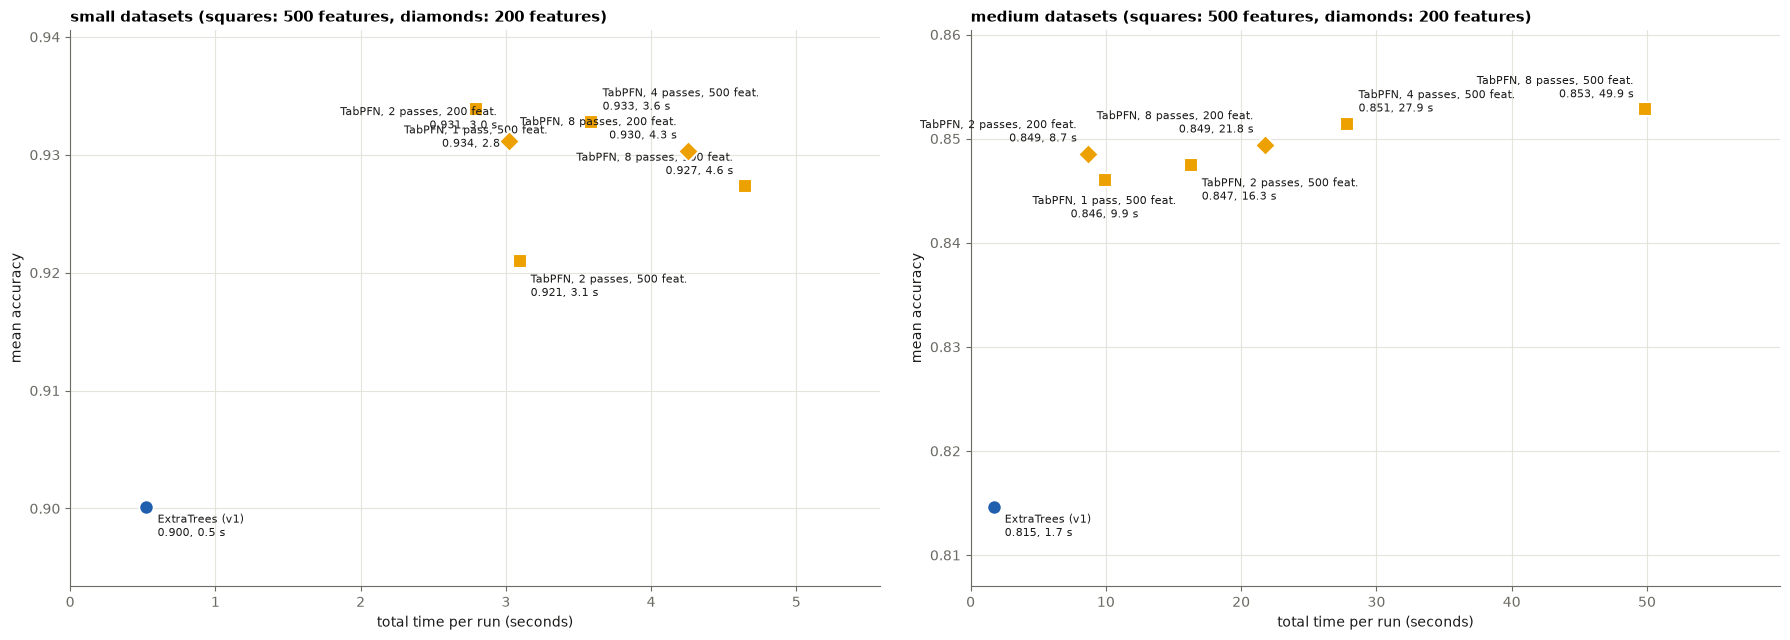

In [3]:
# where each label goes (offset in points, horizontal and vertical alignment): the TabPFN points are close together
LABEL_PLACE = {"extratrees": (8, -4, "left", "top"), "tabpfn-e8f500": (-8, 6, "right", "bottom"),
               "tabpfn-e4f500": (8, 6, "left", "bottom"), "tabpfn-e8f200": (-8, 6, "right", "bottom"),
               "tabpfn-e2f500": (8, -8, "left", "top"), "tabpfn-e2f200": (-8, 6, "right", "bottom"),
               "tabpfn-e1f500": (0, -10, "center", "top")}
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
for ax, group in zip(axes, GROUPS):
    per_config = PER_CONFIG[group]
    for c in MAIN[group]:
        row = per_config.loc[c]
        is_et = c == "extratrees"
        marker = "o" if is_et else ("s" if c.endswith("f500") else "D")   # circle: ExtraTrees, square / diamond: TabPFN
        ax.scatter(row["total_time"], row["accuracy"], s=110, marker=marker,
                   color=COLORS["extratrees"] if is_et else COLORS["tabpfn"], edgecolor="white", linewidth=1.5, zorder=3)
        dx, dy, ha, va = LABEL_PLACE.get(c, (8, -4, "left", "top"))
        ax.annotate(f"{config_label(c, lines=False)}\n{row['accuracy']:.3f}, {row['total_time']:.1f} s",
                    (row["total_time"], row["accuracy"]), xytext=(dx, dy), textcoords="offset points",
                    fontsize=8, color=TEXT, ha=ha, va=va)
    ax.set_xlim(0, per_config["total_time"].max() * 1.2)
    ax.set_xlabel("total time per run (seconds)")
    ax.set_ylabel("mean accuracy")
    ax.set_title(f"{group} datasets (squares: 500 features, diamonds: 200 features)", loc="left")
    ax.grid(True, axis="both")
    ax.margins(y=0.2)
fig.tight_layout()
plt.show()

## 4. Building TabPFN's model once (the model cache)

The same runs with TabPFN's model built for every run and built once per process (`--tabpfn_cache`).

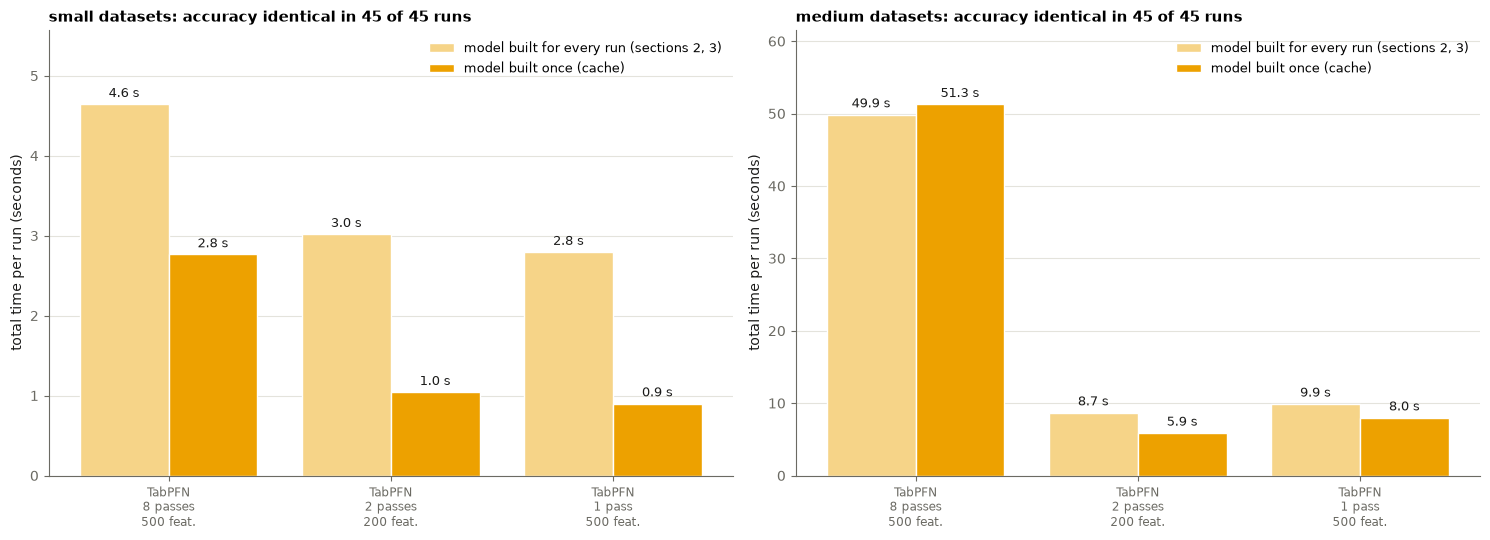

In [4]:
CACHED = ["tabpfn-e8f500", "tabpfn-e2f200", "tabpfn-e1f500"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, group in zip(axes, GROUPS):
    means, identical, total = [], 0, 0
    for config in CACHED:
        without = SWEEP[group][SWEEP[group]["classifier"] == config]
        cached = load(sweep_file(config, group, "-cache"))
        both = without.merge(cached, on=key, suffixes=("", " cached"))   # the same runs without / with the cache
        identical += (both["accuracy"] == both["accuracy cached"]).sum()
        total += len(both)
        means.append((both["total_time"].mean(), both["total_time cached"].mean()))
    x = np.arange(len(CACHED))
    for k, (offset, color, label) in enumerate([(-0.2, COLORS["tabpfn default"], "model built for every run (sections 2, 3)"),
                                                (0.2, COLORS["tabpfn"], "model built once (cache)")]):
        bars = ax.bar(x + offset, [m[k] for m in means], 0.4, color=color, edgecolor="white", label=label)
        ax.bar_label(bars, fmt="{:.1f} s", padding=3, fontsize=9, color=TEXT)
    ax.set_xticks(x, [config_label(c) for c in CACHED], fontsize=8.5)
    ax.set_ylim(0, max(max(m) for m in means) * 1.2)
    ax.set_ylabel("total time per run (seconds)")
    ax.set_title(f"{group} datasets: accuracy identical in {identical} of {total} runs", loc="left")
    ax.legend(loc="upper right", frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 5. The lean extractor (v3), and where we ended

v3's extractor (`quant_tabpfn.py`) gives about 450 features with few near-copies instead of QUANT's thousands. Four
results on the same 15 runs: the two v1 references, TabPFN 2 x 200 on QUANT's features, and v3. Above the bars: the
change against QUANT + ExtraTrees (accuracy) or the time as a multiple of its time.

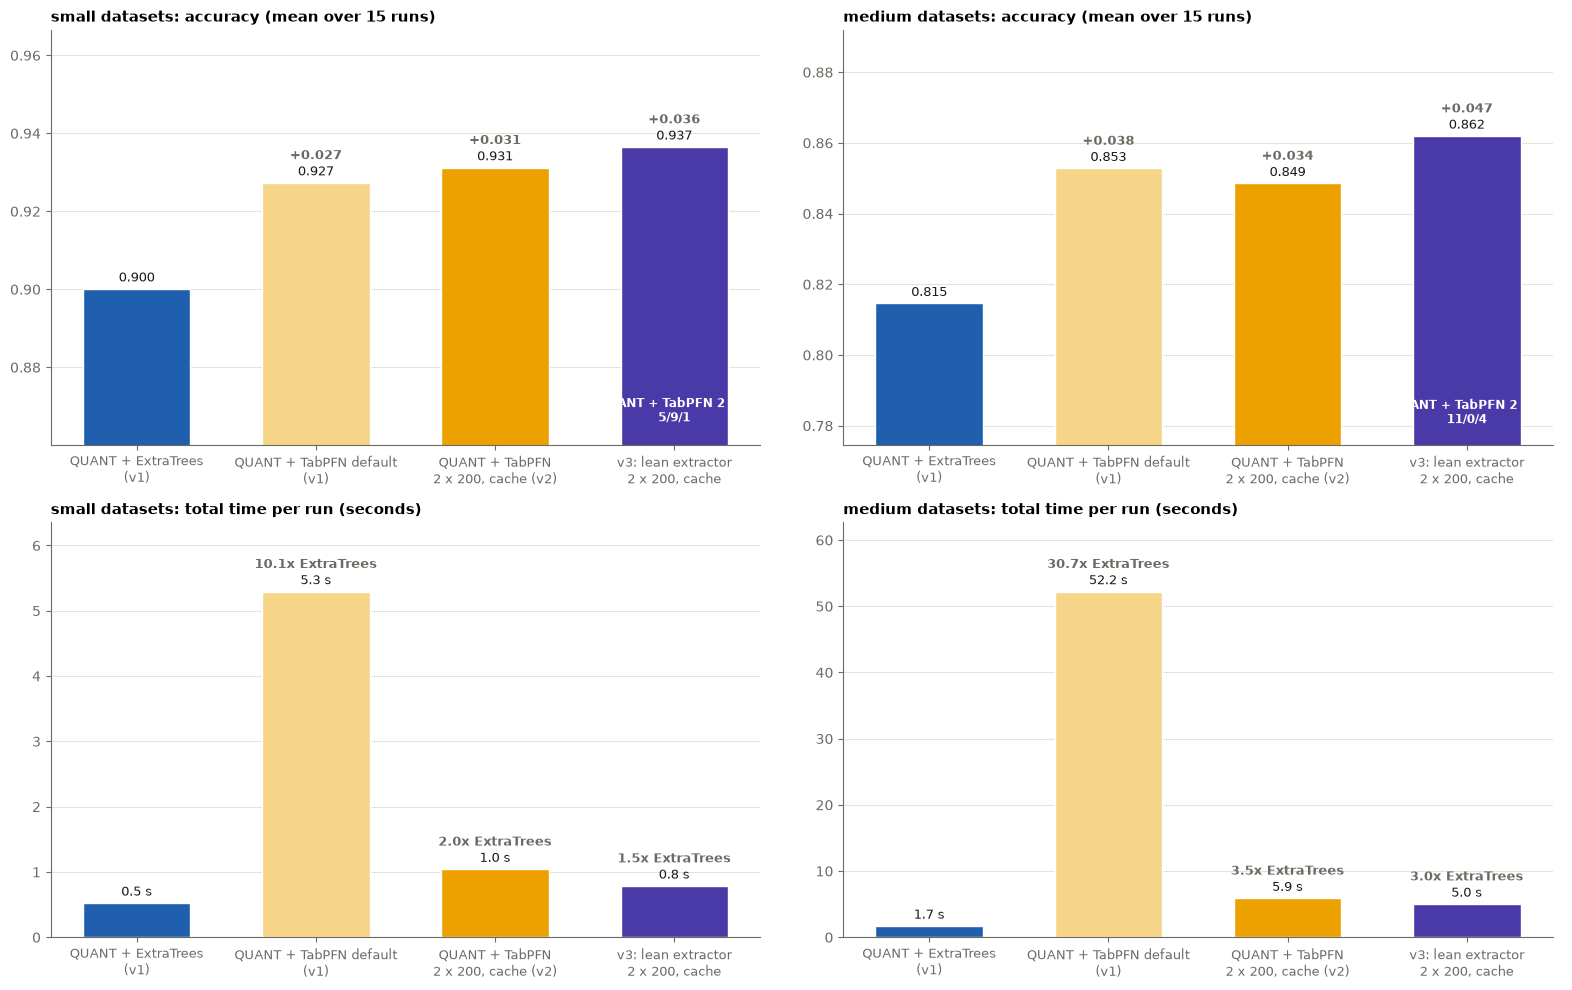

In [5]:
FINAL = ["QUANT + ExtraTrees\n(v1)", "QUANT + TabPFN default\n(v1)", "QUANT + TabPFN\n2 x 200, cache (v2)",
         "v3: lean extractor\n2 x 200, cache"]
FINAL_COLORS = [VERSION_COLORS["v1"], COLORS["tabpfn default"], COLORS["tabpfn"], VERSION_COLORS["v3"]]
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for col, group in enumerate(GROUPS):
    v1 = V1[group]
    runs = [v1[v1["classifier"] == "extratrees"], v1[v1["classifier"] == "tabpfn"],
            load(sweep_file("tabpfn-e2f200", group, "-cache")), load(f"v3_tabpfn-e2f200-both_smoke-{group}_allcores-gpu.csv")]
    better, equal, worse = wdl_counts(runs[3].set_index(key)["accuracy"] - runs[2].set_index(key)["accuracy"])
    for row, (metric, title, fmt) in enumerate([("accuracy", "accuracy (mean over 15 runs)", "{:.3f}"),
                                                ("total_time", "total time per run (seconds)", "{:.1f} s")]):
        ax = axes[row, col]
        values = [r[metric].mean() for r in runs]
        bars = ax.bar(range(len(FINAL)), values, 0.6, color=FINAL_COLORS, edgecolor="white")
        ax.bar_label(bars, fmt=fmt, padding=3, fontsize=9.5, color=TEXT)
        for k in range(1, len(FINAL)):  # against QUANT + ExtraTrees, above the value
            text = signed(values[k] - values[0]) if metric == "accuracy" else f"{values[k] / values[0]:.1f}x ExtraTrees"
            ax.annotate(text, (k, values[k]), xytext=(0, 17), textcoords="offset points", ha="center", fontsize=9,
                        color=MUTED, fontweight="bold")
        if metric == "accuracy":
            ax.set_ylim(min(values) - 0.04, min(1.0, max(values) + 0.03))
            ax.annotate(f"vs QUANT + TabPFN 2 x 200:\n{better}/{equal}/{worse}", (3, min(values) - 0.035), ha="center",
                        va="bottom", fontsize=8.5, color="white", fontweight="bold")
        else:
            ax.set_ylim(0, max(values) * 1.2)
        ax.set_xticks(range(len(FINAL)), FINAL, fontsize=9)
        ax.set_title(f"{group} datasets: {title}", loc="left")
fig.tight_layout()
plt.show()

## 6. Conclusions

- **Fewer passes save most of the time:** on the medium datasets TabPFN's default (8 passes, 500 features) reaches
  0.853 at 49.9 s per run, 2 passes x 200 features 0.849 at 8.7 s.
- **The model cache:** identical results (90 of 90 runs), about 2 s less per run.
- **v3's lean extractor beats QUANT's features at the same cost:** 0.937 / 0.862 (small / medium) against 0.931 /
  0.849, and a little faster.
- **Where we ended:** v3 is more accurate than TabPFN's default (+0.010, +0.009) at 1.5x and 3.0x ExtraTrees' time,
  instead of 10.1x and 30.7x.

Caveat: 5 datasets x 3 resamples per list; only the gap to ExtraTrees is clearly larger than the spread between
resamples.